In [2]:
import sys
import csv
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime

import gender_guesser.detector as gender

from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate

from sklearn import metrics
from sklearn import preprocessing
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import learning_curve
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.ensemble import RandomForestClassifier

In [26]:
import re

def extract_username_features(username):
    """Extracts numeric and linguistic features from a username."""
    name = str(username).strip()
    
    # Basic length and character stats
    length = len(name)
    num_digits = sum(c.isdigit() for c in name)
    num_upper = sum(c.isupper() for c in name)
    num_underscore = name.count('_')
    num_special = len(re.findall(r"[^a-zA-Z0-9_]", name))
    num_vowels = len(re.findall(r"[aeiouAEIOU]", name))
    
    # Ratio features
    digit_ratio = num_digits / length if length > 0 else 0
    vowel_ratio = num_vowels / length if length > 0 else 0
    
    # Gender prediction based on first name
    d = gender.Detector(case_sensitive=False)
    first_part = re.split(r'[_\W]+', name)[0]
    gender_type = d.get_gender(first_part)
    gender_dict = {'female': -2, 'mostly_female': -1, 'unknown': 0, 
                   'andy': 0, 'mostly_male': 1, 'male': 2}
    gender_code = gender_dict.get(gender_type, 0)

    # Return as pandas DataFrame (same style as model expects)
    features = pd.DataFrame([{
        'length': length,
        'num_digits': num_digits,
        'num_upper': num_upper,
        'num_underscore': num_underscore,
        'num_special': num_special,
        'num_vowels': num_vowels,
        'digit_ratio': digit_ratio,
        'vowel_ratio': vowel_ratio,
        'gender_code': gender_code
    }])
    
    return features


In [10]:
def read_datasets():
    """ Reads users profile from csv files """
    real_users = pd.read_csv("Dataset/users.csv")
    fake_users = pd.read_csv("Dataset/fusers.csv")
    
    x = pd.concat([real_users,fake_users])    
    y = len(fake_users)*[0] + len(real_users)*[1]
    
    return x,y

In [11]:
def predict_sex(name):
    d = gender.Detector(case_sensitive=False)
    first_name= str(name).split(' ')[0]
    sex = d.get_gender(u"{}".format(first_name))
    
    sex_code_dict = {'female': -2, 'mostly_female': -1,'unknown':0, 'andy': 0, 'mostly_male':1, 'male': 2}
    code = sex_code_dict[sex]
    
    return code

In [12]:
def extract_features(x):
    lang_list = list(enumerate(np.unique(x['lang'])))
    
    lang_dict = { name : i for i, name in lang_list }             
    
    x.loc[:,'lang_code'] = x['lang'].map( lambda x: lang_dict[x]).astype(int)    
    x.loc[:,'sex_code'] = predict_sex(x['name'])
    
    feature_columns_to_use = ['statuses_count','followers_count','friends_count','favourites_count','listed_count','sex_code','lang_code']
    x = x.loc[:,feature_columns_to_use]
    
    return x

In [13]:
def plot_learning_curve(estimator, title, X, y, ylim=None, cv=None,
                        n_jobs=1, train_sizes=np.linspace(.1, 1.0, 5)):
    plt.figure()
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Training examples")
    plt.ylabel("Score")
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes)
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
             label="Cross-validation score")

    plt.legend(loc="best")
    
    return plt

In [14]:
def plot_confusion_matrix(cm, title='CONFUSION MATRIX', cmap=plt.cm.Reds):
    target_names=['Fake','Genuine']
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(target_names))
    plt.xticks(tick_marks, target_names, rotation=45)
    plt.yticks(tick_marks, target_names)
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [15]:
def train_random_forest(X_train, y_train, X_test):
   

    classifier = RandomForestClassifier()

    classifier.fit(X_train, y_train)

    # Predict class
    y_pred = classifier.predict(X_test)

    return y_pred



In [16]:
x, y = read_datasets()
print("dataset read complete")

dataset read complete


In [17]:
x = extract_features(x)
print(x.columns)

Index(['statuses_count', 'followers_count', 'friends_count',
       'favourites_count', 'listed_count', 'sex_code', 'lang_code'],
      dtype='object')


In [18]:
# splitting train and test data
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.40, random_state=44)

In [19]:
y_pred = train_random_forest(X_train, y_train, X_test)

KeyboardInterrupt: 

Confusion matrix, without normalization
[[516   7]
 [ 64 541]]


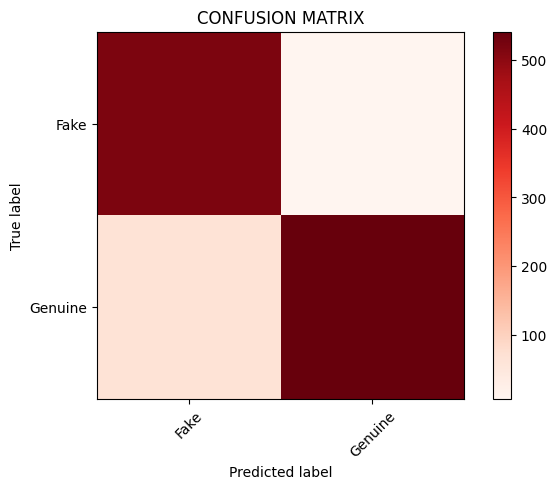

In [20]:
confusionMatrix = confusion_matrix(y_test, y_pred)
print('Confusion matrix, without normalization')
print(confusionMatrix)
plot_confusion_matrix(confusionMatrix)

In [21]:
print(classification_report(y_test, y_pred, target_names=['Fake','Genuine']))


              precision    recall  f1-score   support

        Fake       0.89      0.99      0.94       523
     Genuine       0.99      0.89      0.94       605

    accuracy                           0.94      1128
   macro avg       0.94      0.94      0.94      1128
weighted avg       0.94      0.94      0.94      1128



In [22]:
print('Classification Accuracy on Test dataset: ' ,accuracy_score(y_test, y_pred))


Classification Accuracy on Test dataset:  0.9370567375886525


In [25]:
# === Save the trained Random Forest model ===
import joblib
import os

# Train again or capture model object
classifier = RandomForestClassifier()
classifier.fit(X_train, y_train)

# Create directory for saving model
os.makedirs('model', exist_ok=True)

# Save model details (no scaler used in your script)
model_data = {
    'model': classifier,
    'scaler': None,
    'feature_columns': X_train.columns.tolist()
}

# Save as pickle
joblib.dump(model_data, 'model/random_forest_model.pkl')
print("✅ Model saved successfully at: model/random_forest_model.pkl")


✅ Model saved successfully at: model/random_forest_model.pkl
